In [61]:
import os
import json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

In [62]:
SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [63]:
P = 97                 # prime modulus
TRAIN_FRAC = 0.3       # small training fraction is needed for grokking
HIDDEN = 512
LR = 1e-3
WEIGHT_DECAY = 1.0
OPTIMIZER = "adamw"    # "adamw", "adam", "sgd"
STEPS = 30000           # smoke test; use 20000-50000 on Day 2
LOG_EVERY = 100


In [64]:
pairs = [(a, b) for a in range(P) for b in range(P)]
labels = [(a + b) % P for a, b in pairs]
print("Total examples:", len(pairs))

Total examples: 9409


In [65]:
rng = np.random.RandomState(SEED)
perm = rng.permutation(len(pairs))
n_train = int(TRAIN_FRAC * len(pairs))
train_idx, test_idx = perm[:n_train], perm[n_train:]
print("Train:", len(train_idx), "Test:", len(test_idx))


Train: 2822 Test: 6587


In [66]:

rng = np.random.RandomState(SEED)
perm = rng.permutation(len(pairs))
n_train = int(TRAIN_FRAC * len(pairs))
train_idx, test_idx = perm[:n_train], perm[n_train:]
print("Train:", len(train_idx), "Test:", len(test_idx))


Train: 2822 Test: 6587


In [67]:
def encode(ids):
    a = torch.tensor([pairs[i][0] for i in ids])
    b = torch.tensor([pairs[i][1] for i in ids])
    x = torch.cat([F.one_hot(a, P), F.one_hot(b, P)], dim=1).float()
    y = torch.tensor([labels[i] for i in ids])
    return x.to(device), y.to(device)

x_train, y_train = encode(train_idx)
x_test, y_test = encode(test_idx)
print("x_train:", tuple(x_train.shape), "x_test:", tuple(x_test.shape))

x_train: (2822, 194) x_test: (6587, 194)


In [68]:
def make_model():
    torch.manual_seed(SEED)  # same init every time for fair comparisons
    return nn.Sequential(
        nn.Linear(2 * P, HIDDEN),
        nn.ReLU(),
        nn.Linear(HIDDEN, P),
    ).to(device)

def make_optimizer(model, name, lr, weight_decay):
    if name == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    if name == "adam":
        # plain Adam: weight_decay=0 gives "no regularization" baseline
        return torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    if name == "sgd":
        return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    raise ValueError(f"Unknown optimizer: {name}")

In [69]:
@torch.no_grad()
def evaluate(model, x, y):
    model.eval()
    logits = model(x)
    loss = F.cross_entropy(logits, y).item()
    acc = (logits.argmax(dim=1) == y).float().mean().item()
    model.train()
    return loss, acc

def train(optimizer_name=OPTIMIZER, lr=LR, weight_decay=WEIGHT_DECAY, steps=STEPS):
    model = make_model()
    opt = make_optimizer(model, optimizer_name, lr, weight_decay)
    history = {"step": [], "train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

    for step in range(steps + 1):
        # log first (step 0 = before any update)
        if step % LOG_EVERY == 0:
            tr_loss, tr_acc = evaluate(model, x_train, y_train)
            te_loss, te_acc = evaluate(model, x_test, y_test)
            history["step"].append(step)
            history["train_loss"].append(tr_loss)
            history["test_loss"].append(te_loss)
            history["train_acc"].append(tr_acc)
            history["test_acc"].append(te_acc)
            if step % (LOG_EVERY * 5) == 0:
                print(f"step {step:6d} | train acc {tr_acc:.3f} | test acc {te_acc:.3f} "
                      f"| train loss {tr_loss:.4f} | test loss {te_loss:.4f}")

        if step == steps:
            break

        # one full-batch update
        loss = F.cross_entropy(model(x_train), y_train)
        opt.zero_grad()
        loss.backward()
        opt.step()

    return history


In [44]:

# %% Run the smoke test and save results
history = train()

os.makedirs("results", exist_ok=True)
run_name = f"{OPTIMIZER}_wd{WEIGHT_DECAY}_seed{SEED}"
with open(f"results/{run_name}.json", "w") as f:
    json.dump(history, f)
print("Saved results to", f"results/{run_name}.json")

step      0 | train acc 0.008 | test acc 0.013 | train loss 4.5753 | test loss 4.5759
step    500 | train acc 1.000 | test acc 0.000 | train loss 0.3175 | test loss 9.1587
step   1000 | train acc 1.000 | test acc 0.000 | train loss 0.1261 | test loss 9.0803
step   1500 | train acc 1.000 | test acc 0.000 | train loss 0.0820 | test loss 8.6731
step   2000 | train acc 1.000 | test acc 0.000 | train loss 0.0580 | test loss 8.1999
step   2500 | train acc 1.000 | test acc 0.000 | train loss 0.0429 | test loss 7.6660
step   3000 | train acc 1.000 | test acc 0.001 | train loss 0.0323 | test loss 7.0750
step   3500 | train acc 1.000 | test acc 0.002 | train loss 0.0249 | test loss 6.5004
step   4000 | train acc 1.000 | test acc 0.005 | train loss 0.0196 | test loss 6.0288
step   4500 | train acc 1.000 | test acc 0.010 | train loss 0.0157 | test loss 5.6771
step   5000 | train acc 1.000 | test acc 0.017 | train loss 0.0126 | test loss 5.3919
step   5500 | train acc 1.000 | test acc 0.023 | train

T_train=300  T_test=22200  delay=21900


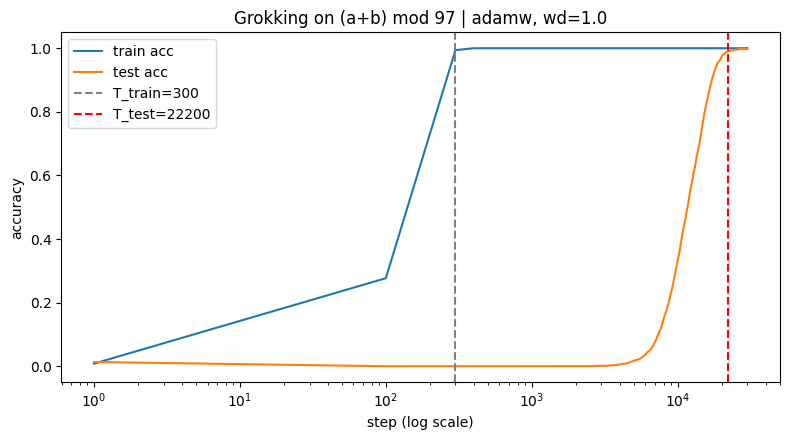

(300, 22200, 21900)

In [45]:
import matplotlib.pyplot as plt

def first_step_above(history, key, thresh=0.99):
    for s, v in zip(history["step"], history[key]):
        if v >= thresh:
            return s
    return None

def plot_run(history, title, save_path=None):
    t_train = first_step_above(history, "train_acc")
    t_test = first_step_above(history, "test_acc")
    delay = (t_test - t_train) if (t_train is not None and t_test is not None) else None
    print(f"T_train={t_train}  T_test={t_test}  delay={delay}")

    steps_ = [max(s, 1) for s in history["step"]]  # avoid log(0)
    plt.figure(figsize=(8, 4.5))
    plt.plot(steps_, history["train_acc"], label="train acc")
    plt.plot(steps_, history["test_acc"], label="test acc")
    if t_train:
        plt.axvline(max(t_train, 1), ls="--", c="gray", label=f"T_train={t_train}")
    if t_test:
        plt.axvline(t_test, ls="--", c="red", label=f"T_test={t_test}")
    plt.xscale("log")
    plt.xlabel("step (log scale)")
    plt.ylabel("accuracy")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    plt.show()
    return t_train, t_test, delay

plot_run(history,
         title=f"Grokking on (a+b) mod {P} | {OPTIMIZER}, wd={WEIGHT_DECAY}",
         save_path=f"results/{run_name}.png")

Day2


In [46]:
import os, json, time
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

D2_OPTIMIZER = "adamw"
D2_LR = 1e-3
D2_WEIGHT_DECAY = 2.0
D2_STEPS = 30000          # raise to 60000 if test accuracy has not jumped yet
STOP_AFTER_GROK = 2000    # keep training this many steps after test acc hits 99%, then stop
THRESH = 0.99


In [47]:
def should_log(step):
    # every 10 steps early (the memorization phase is fast), every 100 later
    return step % 10 == 0 if step < 1000 else step % 100 == 0

def train_long(optimizer_name=D2_OPTIMIZER, lr=D2_LR, weight_decay=D2_WEIGHT_DECAY,
               steps=D2_STEPS, stop_after_grok=STOP_AFTER_GROK, verbose=True):
    model = make_model()
    opt = make_optimizer(model, optimizer_name, lr, weight_decay)
    h = {"step": [], "train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
    grok_step = None
    start = time.time()

    for step in range(steps + 1):
        if should_log(step):
            tr_loss, tr_acc = evaluate(model, x_train, y_train)
            te_loss, te_acc = evaluate(model, x_test, y_test)
            h["step"].append(step)
            h["train_loss"].append(tr_loss); h["test_loss"].append(te_loss)
            h["train_acc"].append(tr_acc);  h["test_acc"].append(te_acc)

            if verbose and step % 1000 == 0:
                print(f"step {step:6d} | train acc {tr_acc:.3f} | test acc {te_acc:.3f} "
                      f"| train loss {tr_loss:.4f} | test loss {te_loss:.4f} "
                      f"| {time.time()-start:.0f}s")

            if grok_step is None and te_acc >= THRESH:
                grok_step = step
                if verbose:
                    print(f">>> test accuracy reached {THRESH:.0%} at step {step}")
            if grok_step is not None and step >= grok_step + stop_after_grok:
                if verbose:
                    print("Stopping: ran long enough after grokking.")
                break

        if step == steps:
            break

        loss = F.cross_entropy(model(x_train), y_train)
        opt.zero_grad()
        loss.backward()
        opt.step()

    return h


In [48]:
history_d2 = train_long()


step      0 | train acc 0.008 | test acc 0.013 | train loss 4.5753 | test loss 4.5759 | 0s
step   1000 | train acc 1.000 | test acc 0.000 | train loss 0.3319 | test loss 7.6373 | 1s
step   2000 | train acc 1.000 | test acc 0.000 | train loss 0.1801 | test loss 6.2080 | 3s
step   3000 | train acc 1.000 | test acc 0.007 | train loss 0.1216 | test loss 5.0938 | 4s
step   4000 | train acc 1.000 | test acc 0.042 | train loss 0.0859 | test loss 4.2568 | 5s
step   5000 | train acc 1.000 | test acc 0.152 | train loss 0.0619 | test loss 3.4620 | 7s
step   6000 | train acc 1.000 | test acc 0.341 | train loss 0.0453 | test loss 2.7095 | 8s
step   7000 | train acc 1.000 | test acc 0.495 | train loss 0.0342 | test loss 2.2461 | 9s
step   8000 | train acc 1.000 | test acc 0.635 | train loss 0.0260 | test loss 1.8582 | 10s
step   9000 | train acc 1.000 | test acc 0.743 | train loss 0.0200 | test loss 1.5629 | 12s
step  10000 | train acc 1.000 | test acc 0.809 | train loss 0.0157 | test loss 1.3396 | 

In [49]:
def measure(h):
    t_train = first_step_above(h, "train_acc", THRESH)
    t_test = first_step_above(h, "test_acc", THRESH)
    delay = (t_test - t_train) if (t_train is not None and t_test is not None) else None
    return t_train, t_test, delay

def plot_run_2panel(h, title, save_path=None):
    t_train, t_test, delay = measure(h)
    print(f"T_train={t_train}  T_test={t_test}  delay={delay}")
    xs = [max(s, 1) for s in h["step"]]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
    ax1.plot(xs, h["train_acc"], label="train acc")
    ax1.plot(xs, h["test_acc"], label="test acc")
    ax2.plot(xs, h["train_loss"], label="train loss")
    ax2.plot(xs, h["test_loss"], label="test loss")
    for ax in (ax1, ax2):
        if t_train: ax.axvline(max(t_train, 1), ls="--", c="gray")
        if t_test:  ax.axvline(t_test, ls="--", c="red")
    ax1.set_ylabel("accuracy"); ax2.set_ylabel("loss")
    ax2.set_xlabel("step (log scale)")
    ax1.set_xscale("log")
    ttl = title + (f"\nT_train={t_train}, T_test={t_test}, delay={delay}" if delay is not None else "")
    ax1.set_title(ttl)
    ax1.legend(); ax2.legend()
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    plt.show()
    return t_train, t_test, delay


T_train=340  T_test=19000  delay=18660


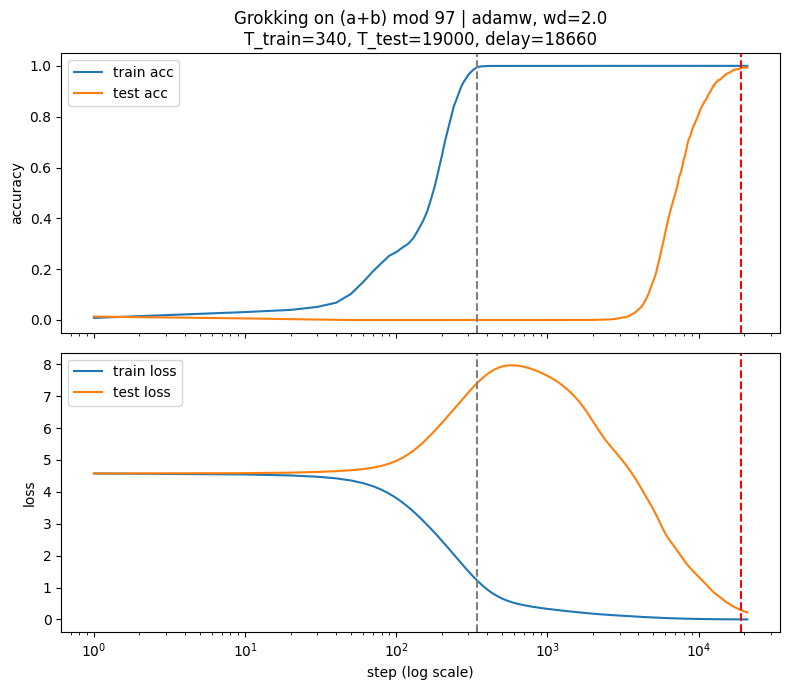

In [50]:
os.makedirs("results", exist_ok=True)
run_name_d2 = f"{D2_OPTIMIZER}_wd{D2_WEIGHT_DECAY}_seed{SEED}_long"
t_train, t_test, delay = plot_run_2panel(
    history_d2,
    title=f"Grokking on (a+b) mod {P} | {D2_OPTIMIZER}, wd={D2_WEIGHT_DECAY}",
    save_path=f"results/{run_name_d2}.png",
)


In [51]:
with open(f"results/{run_name_d2}.json", "w") as f:
    json.dump({"history": history_d2,
               "T_train": t_train, "T_test": t_test, "delay": delay,
               "config": {"optimizer": D2_OPTIMIZER, "lr": D2_LR,
                          "weight_decay": D2_WEIGHT_DECAY, "steps": D2_STEPS,
                          "p": P, "seed": SEED}}, f)
print("Saved:", run_name_d2)


Saved: adamw_wd2.0_seed0_long


In [52]:
# %% FALLBACK (only if test accuracy did NOT jump after 30k-60k steps)
# Change ONE thing at a time, in this order, and rerun the cells above:
#   1) TRAIN_FRAC = 0.3 in the Day 1 config, then rerun the Day 1 split/encode cells
#   2) D2_WEIGHT_DECAY = 2.0  (or 0.5)
#   3) HIDDEN = 512 in the Day 1 config, then rerun the model cell
# Keep a note of every change, because failed settings are also useful results.

DAY3

In [86]:
import os, re, json, time, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

# Day 3: use SEEDS = [0] to check every optimizer works. Day 4-5: SEEDS = [0, 1, 2].
SEEDS = [0, 1, 2]
MAX_STEPS = 40000          # budget per run; runs that never reach 99% test acc use all of it
STOP_AFTER_GROK = 1000     # keep training this many steps after test acc hits 99%, then stop
THRESH = 0.99
RUN_DIR = "results/runs"   # to survive Colab resets, use e.g. "/content/drive/MyDrive/grokking_runs"

EXPERIMENTS = {
    "AdamW (wd=2.0)":      dict(optimizer="adamw", lr=1e-3, weight_decay=2.0),
    "Adam (wd=0)":         dict(optimizer="adam",  lr=1e-3, weight_decay=0.0),
    "SGD+momentum (wd=0)": dict(optimizer="sgd",   lr=0.1,  weight_decay=0.0),
    "AdamW (wd=2.0, hidden=512)": dict(optimizer="adamw", lr=1e-3, weight_decay=2.0, hidden=512),
    # Optional extras (uncomment to add; each adds runs):
    "SGD+momentum (wd=1e-3)": dict(optimizer="sgd", lr=0.1, weight_decay=1e-3),
    "AdamW (wd=1.0)":         dict(optimizer="adamw", lr=1e-3, weight_decay=1.0),
    # Width test (same setup, only hidden size changes):
    "AdamW (wd=2.0, hidden=512)": dict(optimizer="adamw", lr=1e-3, weight_decay=2.0, hidden=512),
    "SGD+momentum (wd=0.02)":  dict(optimizer="sgd", lr=0.1, weight_decay=0.02),
    "SGD+momentum (wd=0.002)": dict(optimizer="sgd", lr=0.1, weight_decay=0.002),
}

os.makedirs(RUN_DIR, exist_ok=True)

# Sanity check: this comparison assumes the base setup (train fraction 0.3, hidden 256).
assert abs(TRAIN_FRAC - 0.3) < 1e-9, (
    "Set TRAIN_FRAC = 0.3 in the Day 1 config, then rerun the Day 1 split and encode cells.")
print("Train examples:", len(train_idx), "| default hidden:", HIDDEN, "| device:", device)
# Hidden size can be set per experiment with a "hidden" key (default: HIDDEN from the Day 1 config).


Train examples: 2822 | default hidden: 512 | device: cuda


In [87]:
# %% Helpers: logging schedule, measurement, one run
def should_log(step):
    # every 10 steps early (memorization is fast), every 100 later
    return step % 10 == 0 if step < 1000 else step % 100 == 0

def first_step(h, key, thresh=THRESH):
    for s, v in zip(h["step"], h[key]):
        if v >= thresh:
            return s
    return None

def safe_name(name):
    return re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_")

def run_path(name, seed):
    return f"{RUN_DIR}/{safe_name(name)}_seed{seed}.json"

def run_one(name, cfg, seed):
    """Train one (experiment, seed). Returns the saved result dict. Skips if already done."""
    path = run_path(name, seed)
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)

    torch.manual_seed(seed)
    hid = cfg.get("hidden", HIDDEN)
    model = nn.Sequential(nn.Linear(2 * P, hid), nn.ReLU(), nn.Linear(hid, P)).to(device)
    opt = make_optimizer(model, cfg["optimizer"], cfg["lr"], cfg["weight_decay"])
    h = {"step": [], "train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
    grok_step, diverged, start = None, False, time.time()

    for step in range(MAX_STEPS + 1):
        if should_log(step):
            tr_loss, tr_acc = evaluate(model, x_train, y_train)
            te_loss, te_acc = evaluate(model, x_test, y_test)
            h["step"].append(step)
            h["train_loss"].append(tr_loss); h["test_loss"].append(te_loss)
            h["train_acc"].append(tr_acc);  h["test_acc"].append(te_acc)
            if not np.isfinite(tr_loss):
                diverged = True
                break
            if grok_step is None and te_acc >= THRESH:
                grok_step = step
            if grok_step is not None and step >= grok_step + STOP_AFTER_GROK:
                break
        if step == MAX_STEPS:
            break
        loss = F.cross_entropy(model(x_train), y_train)
        opt.zero_grad()
        loss.backward()
        opt.step()

    t_train, t_test = first_step(h, "train_acc"), first_step(h, "test_acc")
    result = {
        "name": name, "seed": seed, "config": cfg, "history": h,
        "T_train": t_train, "T_test": t_test,
        "delay": (t_test - t_train) if (t_train is not None and t_test is not None) else None,
        "final_train_acc": h["train_acc"][-1], "final_test_acc": h["test_acc"][-1],
        "steps_run": h["step"][-1], "diverged": diverged,
        "seconds": round(time.time() - start, 1),
    }
    with open(path, "w") as f:
        json.dump(result, f)
    return result


In [88]:
for name, cfg in EXPERIMENTS.items():
    for seed in SEEDS:
        existed = os.path.exists(run_path(name, seed))
        r = run_one(name, cfg, seed)
        tag = "(cached)" if existed else f"({r['seconds']}s)"
        print(f"{name:24s} seed {seed} | T_train={r['T_train']} T_test={r['T_test']} "
              f"delay={r['delay']} | final test acc {r['final_test_acc']:.3f} "
              f"| steps run {r['steps_run']} {tag}")

AdamW (wd=2.0)           seed 0 | T_train=340 T_test=19000 delay=18660 | final test acc 0.994 | steps run 20000 (cached)
AdamW (wd=2.0)           seed 1 | T_train=190 T_test=11800 delay=11610 | final test acc 0.996 | steps run 12800 (cached)
AdamW (wd=2.0)           seed 2 | T_train=190 T_test=11800 delay=11610 | final test acc 0.996 | steps run 12800 (cached)
Adam (wd=0)              seed 0 | T_train=270 T_test=None delay=None | final test acc 0.000 | steps run 40000 (cached)
Adam (wd=0)              seed 1 | T_train=170 T_test=None delay=None | final test acc 0.000 | steps run 40000 (cached)
Adam (wd=0)              seed 2 | T_train=170 T_test=None delay=None | final test acc 0.000 | steps run 40000 (cached)
SGD+momentum (wd=0)      seed 0 | T_train=2400 T_test=None delay=None | final test acc 0.000 | steps run 40000 (cached)
SGD+momentum (wd=0)      seed 1 | T_train=2100 T_test=None delay=None | final test acc 0.000 | steps run 40000 (cached)
SGD+momentum (wd=0)      seed 2 | T_trai

In [89]:
def load_runs():
    rows = []
    for p in sorted(glob.glob(f"{RUN_DIR}/*.json")):
        with open(p) as f:
            r = json.load(f)
        rows.append({k: r.get(k) for k in
                     ["name", "seed", "T_train", "T_test", "delay",
                      "final_train_acc", "final_test_acc", "steps_run", "diverged"]})
    df = pd.DataFrame(rows)
    for c in ["T_train", "T_test", "delay"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")   # None -> NaN ("did not generalize")
    return df

def summarise(df):
    out = []
    for name, g in df.groupby("name"):
        ok = g.dropna(subset=["delay"])
        out.append({
            "experiment": name,
            "runs": len(g),
            "grokked": f"{len(ok)}/{len(g)}",
            "mean_delay": ok["delay"].mean() if len(ok) else np.nan,
            "std_delay": ok["delay"].std(ddof=1) if len(ok) > 1 else np.nan,
            "min_delay": ok["delay"].min() if len(ok) else np.nan,
            "max_delay": ok["delay"].max() if len(ok) else np.nan,
            "mean_T_train": g["T_train"].mean(),
            "mean_final_test_acc": g["final_test_acc"].mean(),
        })
    return pd.DataFrame(out)

runs_df = load_runs()
summary_df = summarise(runs_df)
runs_df.to_csv("results/all_runs.csv", index=False)
summary_df.to_csv("results/summary.csv", index=False)
print(runs_df.to_string(index=False))
print()
print(summary_df.round(1).to_string(index=False))

                      name  seed  T_train  T_test   delay  final_train_acc  final_test_acc  steps_run  diverged
            AdamW (wd=1.0)     0    180.0 15800.0 15620.0         1.000000        0.996053      16800     False
            AdamW (wd=1.0)     1    180.0 16100.0 15920.0         1.000000        0.995749      17100     False
            AdamW (wd=1.0)     2    180.0 16500.0 16320.0         1.000000        0.996053      17500     False
AdamW (wd=2.0, hidden=512)     0    190.0 11800.0 11610.0         1.000000        0.994838      12800     False
AdamW (wd=2.0, hidden=512)     1    190.0 11800.0 11610.0         1.000000        0.996205      12800     False
AdamW (wd=2.0, hidden=512)     2    190.0 11800.0 11610.0         1.000000        0.995597      12800     False
            AdamW (wd=2.0)     0    340.0 19000.0 18660.0         1.000000        0.993776      20000     False
            AdamW (wd=2.0)     1    190.0 11800.0 11610.0         1.000000        0.996205      12800   

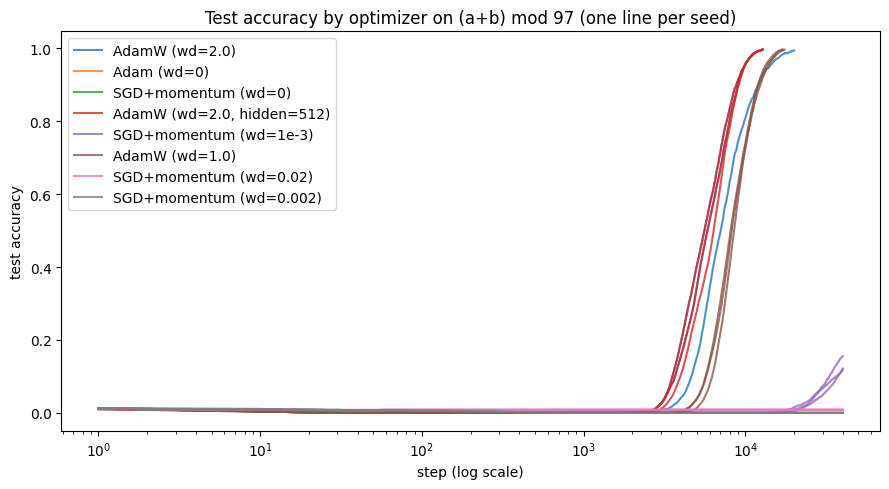

In [90]:
def load_history(name, seed):
    with open(run_path(name, seed)) as f:
        return json.load(f)["history"]

def plot_overlay(save_path="results/overlay_test_acc.png"):
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    plt.figure(figsize=(9, 5))
    for i, name in enumerate(EXPERIMENTS):
        first = True
        for seed in SEEDS:
            if not os.path.exists(run_path(name, seed)):
                continue
            h = load_history(name, seed)
            xs = [max(s, 1) for s in h["step"]]
            plt.plot(xs, h["test_acc"], color=colors[i % len(colors)], alpha=0.8, lw=1.5,
                     label=name if first else None)
            first = False
    plt.xscale("log")
    plt.xlabel("step (log scale)"); plt.ylabel("test accuracy")
    plt.title(f"Test accuracy by optimizer on (a+b) mod {P} (one line per seed)")
    plt.legend(); plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()

plot_overlay()



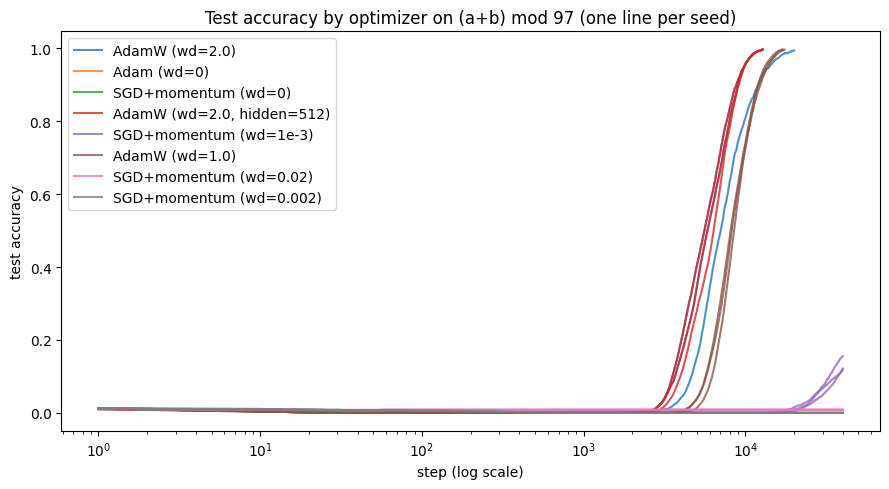

In [91]:
# %% Plot 1: test accuracy for every run, colored by experiment (log x-axis)
def load_history(name, seed):
    with open(run_path(name, seed)) as f:
        return json.load(f)["history"]

def plot_overlay(save_path="results/overlay_test_acc.png"):
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    plt.figure(figsize=(9, 5))
    for i, name in enumerate(EXPERIMENTS):
        first = True
        for seed in SEEDS:
            if not os.path.exists(run_path(name, seed)):
                continue
            h = load_history(name, seed)
            xs = [max(s, 1) for s in h["step"]]
            plt.plot(xs, h["test_acc"], color=colors[i % len(colors)], alpha=0.8, lw=1.5,
                     label=name if first else None)
            first = False
    plt.xscale("log")
    plt.xlabel("step (log scale)"); plt.ylabel("test accuracy")
    plt.title(f"Test accuracy by optimizer on (a+b) mod {P} (one line per seed)")
    plt.legend(); plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()

plot_overlay()


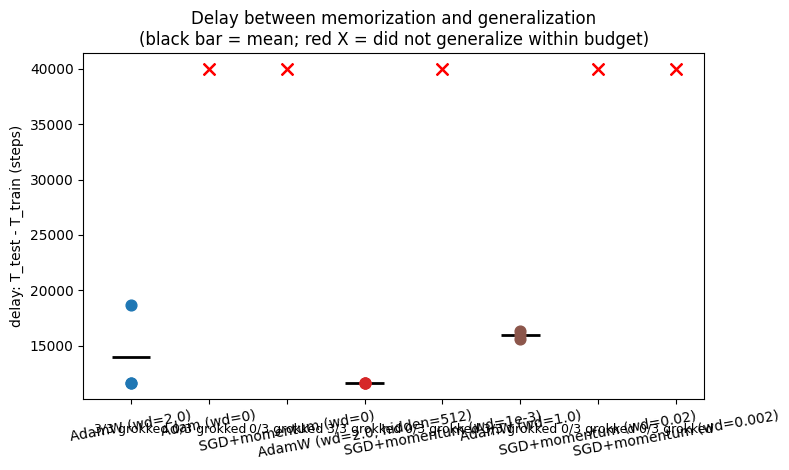

In [92]:
# %% Plot 2: delay (T_test - T_train) per run; runs that never generalized are marked with X
def plot_delays(df, save_path="results/delay_by_optimizer.png"):
    names = list(EXPERIMENTS.keys())
    plt.figure(figsize=(8, 4.8))
    for i, name in enumerate(names):
        g = df[df["name"] == name]
        ok, bad = g.dropna(subset=["delay"]), g[g["delay"].isna()]
        plt.scatter([i] * len(ok), ok["delay"], s=60, zorder=3)
        if len(ok):
            plt.hlines(ok["delay"].mean(), i - 0.25, i + 0.25, colors="k", lw=2)
        if len(bad):
            plt.scatter([i] * len(bad), [MAX_STEPS] * len(bad), marker="x", c="red", s=70, zorder=3)
        plt.text(i, -0.07, f"{len(ok)}/{len(g)} grokked", ha="center", va="top",
                 transform=plt.gca().get_xaxis_transform(), fontsize=9)
    plt.xticks(range(len(names)), names, rotation=10)
    plt.ylabel("delay: T_test - T_train (steps)")
    plt.title("Delay between memorization and generalization\n(black bar = mean; red X = did not generalize within budget)")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

plot_delays(runs_df)


In [93]:
print(HIDDEN, TRAIN_FRAC)
print(sum(p.numel() for p in make_model().parameters()))

512 0.3
149601
